# Figures of the paper
Each section produces one figure in `Figures/` with the file name used in `manuscript.tex`.

| File | Label | Content |
|---|---|---|
| `Figure_2.pdf` | `fig:wind` | Training, validation and test wind profiles |
| `Figure_3.pdf` | `fig:pitch_selection` | Generated power for four pitch increments |
| `Figure_4.pdf` | `fig:validation_results` | Generated power, DDQN vs ROSCO, validation scenarios |
| `Figure_5.pdf` | `fig:pitch_rate_sensitivity` | Scaled STD versus pitch rate: 10 m/s sawtooth and 11 m/s TI = 10 % (with adaptive rule) |

`Figure_1.pdf` (power curve and operating regions) is generated by `curva34.ipynb` in the paper folder.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from utils import load_fast_file, window, FIG_DIR

FIG_DIR.mkdir(exist_ok=True)

## Figure 2: wind profiles

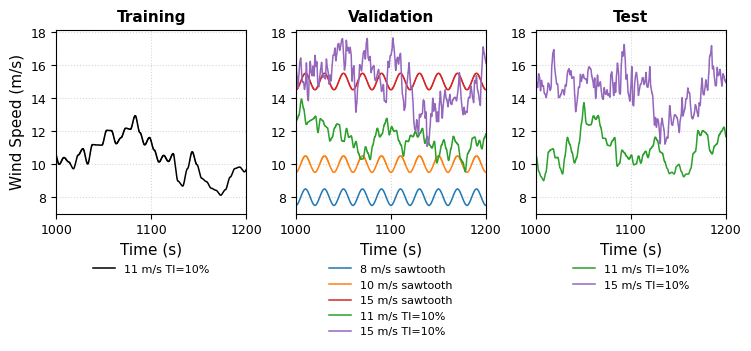

In [2]:
# (label, file, colour) per panel; ROSCO runs share the inflow of the DDQN runs
PROFILES = {
    "Training": [("11 m/s TI=10%", "train_11ti10_rosco.out", "black")],
    "Validation": [
        ("8 m/s sawtooth",  "val_saw08_rosco.out",  "#1f77b4"),
        ("10 m/s sawtooth", "val_saw10_rosco.out",  "#ff7f0e"),
        ("15 m/s sawtooth", "val_saw15_rosco.out",  "#d62728"),
        ("11 m/s TI=10%",   "val_11ti10_rosco.out", "#2ca02c"),
        ("15 m/s TI=10%",   "val_15ti10_rosco.out", "#9467bd"),
    ],
    "Test": [
        ("11 m/s TI=10%", "test_11ti10_rosco.out", "#2ca02c"),
        ("15 m/s TI=10%", "test_15ti10_rosco.out", "#9467bd"),
    ],
}
t_min, t_max = 1000, 1200

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.labelsize": 11,
                     "axes.titlesize": 11, "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42})

fig, axs = plt.subplots(1, 3, figsize=(7.4, 3.4), sharey=True, constrained_layout=True)
for ax, (group, curves) in zip(axs, PROFILES.items()):
    for label, fname, color in curves:
        d = window(load_fast_file(fname)[0], t_min, t_max)
        ax.plot(d["Time"], d["Wind1VelX"], color=color, linewidth=1.1, label=label)
    ax.set_title(group, fontweight="bold")
    ax.set_xlabel("Time (s)")
    ax.set_xlim(t_min, t_max)
    ax.set_xticks([1000, 1100, 1200])
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, ncol=1)
axs[0].set_ylabel("Wind Speed (m/s)")

plt.savefig(FIG_DIR / "Figure_2.pdf", bbox_inches="tight")
plt.show()

## Figure 3: pitch increment selection (training wind)

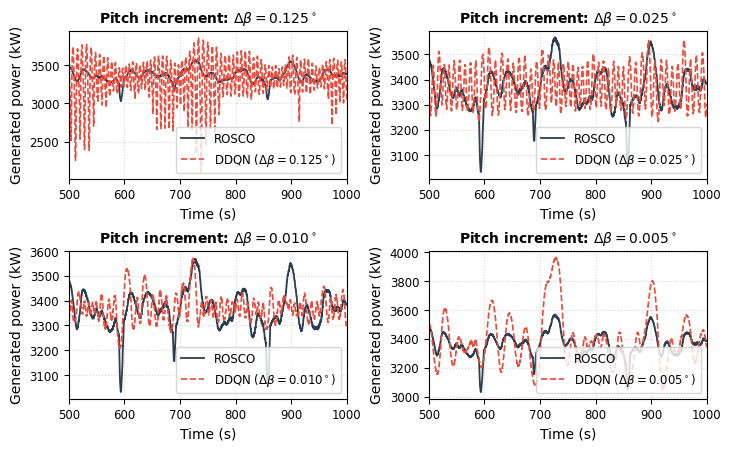

In [3]:
INCREMENTS = {
    "0.125": "train_11ti10_ddqn_db0.125.out",
    "0.025": "train_11ti10_ddqn_db0.025.out",
    "0.010": "train_11ti10_ddqn_db0.010.out",
    "0.005": "train_11ti10_ddqn_db0.005.out",
}
t_min, t_max = 500, 1000

plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "axes.labelsize": 10,
                     "axes.titlesize": 10, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5})

rosco, units = load_fast_file("train_11ti10_rosco.out")
rosco = window(rosco, t_min, t_max)

fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.4), constrained_layout=True)
for ax, (step, fname) in zip(axs.flatten(), INCREMENTS.items()):
    d = window(load_fast_file(fname)[0], t_min, t_max)
    ax.plot(rosco["Time"], rosco["GenPwr"], label="ROSCO", color="#2c3e50", linewidth=1.3)
    ax.plot(d["Time"], d["GenPwr"], label=rf"DDQN ($\Delta\beta={step}^\circ$)",
            color="#e74c3c", linestyle="--", linewidth=1.2)
    ax.set_title(rf"Pitch increment: $\Delta\beta={step}^\circ$", fontweight="bold")
    ax.set_xlabel(f"Time ({units['Time']})")
    ax.set_ylabel(f"Generated power ({units['GenPwr']})")
    ax.set_xlim(t_min, t_max)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="lower right", frameon=True)

plt.savefig(FIG_DIR / "Figure_3.pdf", bbox_inches="tight")
plt.show()

## Figure 4: generated power in the validation scenarios (no scaling)

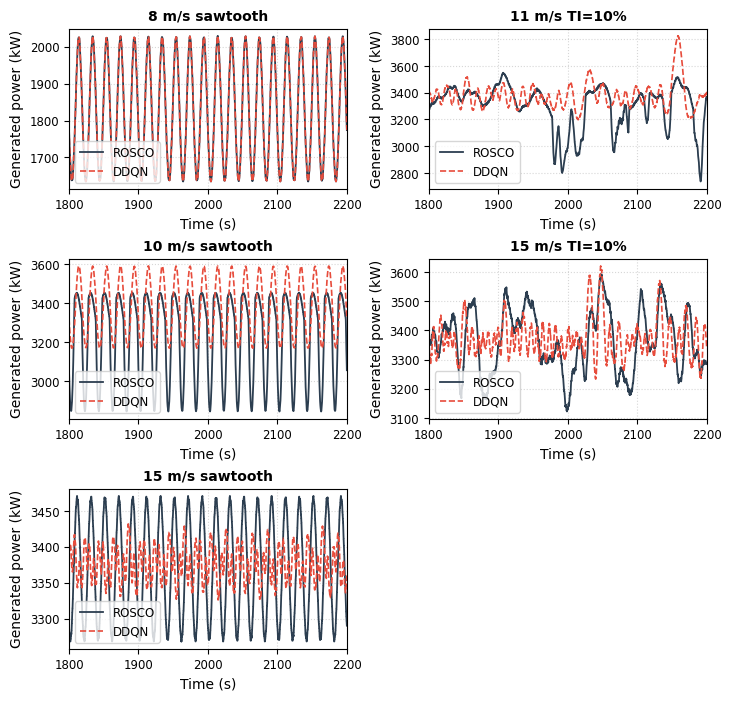

In [4]:
# Sawtooth profiles in the left column, turbulent profiles in the right column
SAWTOOTH = {
    "8 m/s sawtooth":  ("val_saw08_rosco.out", "val_saw08_ddqn_0.4dps.out"),
    "10 m/s sawtooth": ("val_saw10_rosco.out", "val_saw10_ddqn_0.4dps.out"),
    "15 m/s sawtooth": ("val_saw15_rosco.out", "val_saw15_ddqn_0.4dps.out"),
}
TURBULENT = {
    "11 m/s TI=10%": ("val_11ti10_rosco.out", "val_11ti10_ddqn_0.4dps.out"),
    "15 m/s TI=10%": ("val_15ti10_rosco.out", "val_15ti10_ddqn_0.4dps.out"),
}
t_min, t_max = 1800, 2200

n_rows = max(len(SAWTOOTH), len(TURBULENT))
fig, axs = plt.subplots(n_rows, 2, figsize=(7.2, 2.3 * n_rows), squeeze=False, constrained_layout=True)
for ax in axs.flatten():
    ax.axis("off")

for col, group in enumerate([SAWTOOTH, TURBULENT]):
    for row, (name, (f_ro, f_rl)) in enumerate(group.items()):
        ax = axs[row, col]
        ax.axis("on")
        ro, units = load_fast_file(f_ro)
        rl, _ = load_fast_file(f_rl)
        ro, rl = window(ro, t_min, t_max), window(rl, t_min, t_max)
        ax.plot(ro["Time"], ro["GenPwr"], label="ROSCO", color="#2c3e50", linewidth=1.3)
        ax.plot(rl["Time"], rl["GenPwr"], label="DDQN", color="#e74c3c", linestyle="--", linewidth=1.2)
        ax.set_title(name, fontweight="bold")
        ax.set_xlabel(f"Time ({units['Time']})")
        ax.set_ylabel(f"Generated power ({units['GenPwr']})")
        ax.set_xlim(t_min, t_max)
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend(loc="lower left", frameon=True)

plt.savefig(FIG_DIR / "Figure_4.pdf", bbox_inches="tight")
plt.show()

## Figure 5: pitch-rate scaling
Data from `Figures/fig5_data.csv`, generated by `03_pitch_rate_scaling.ipynb` (run it first).

* A) 10 m/s sawtooth: fixed nominal rates (equally spaced categories).
* B) 11 m/s TI = 10 %: fixed nominal rates and, on the right, the two-level adaptive rule (0.8/0.3 °/s).

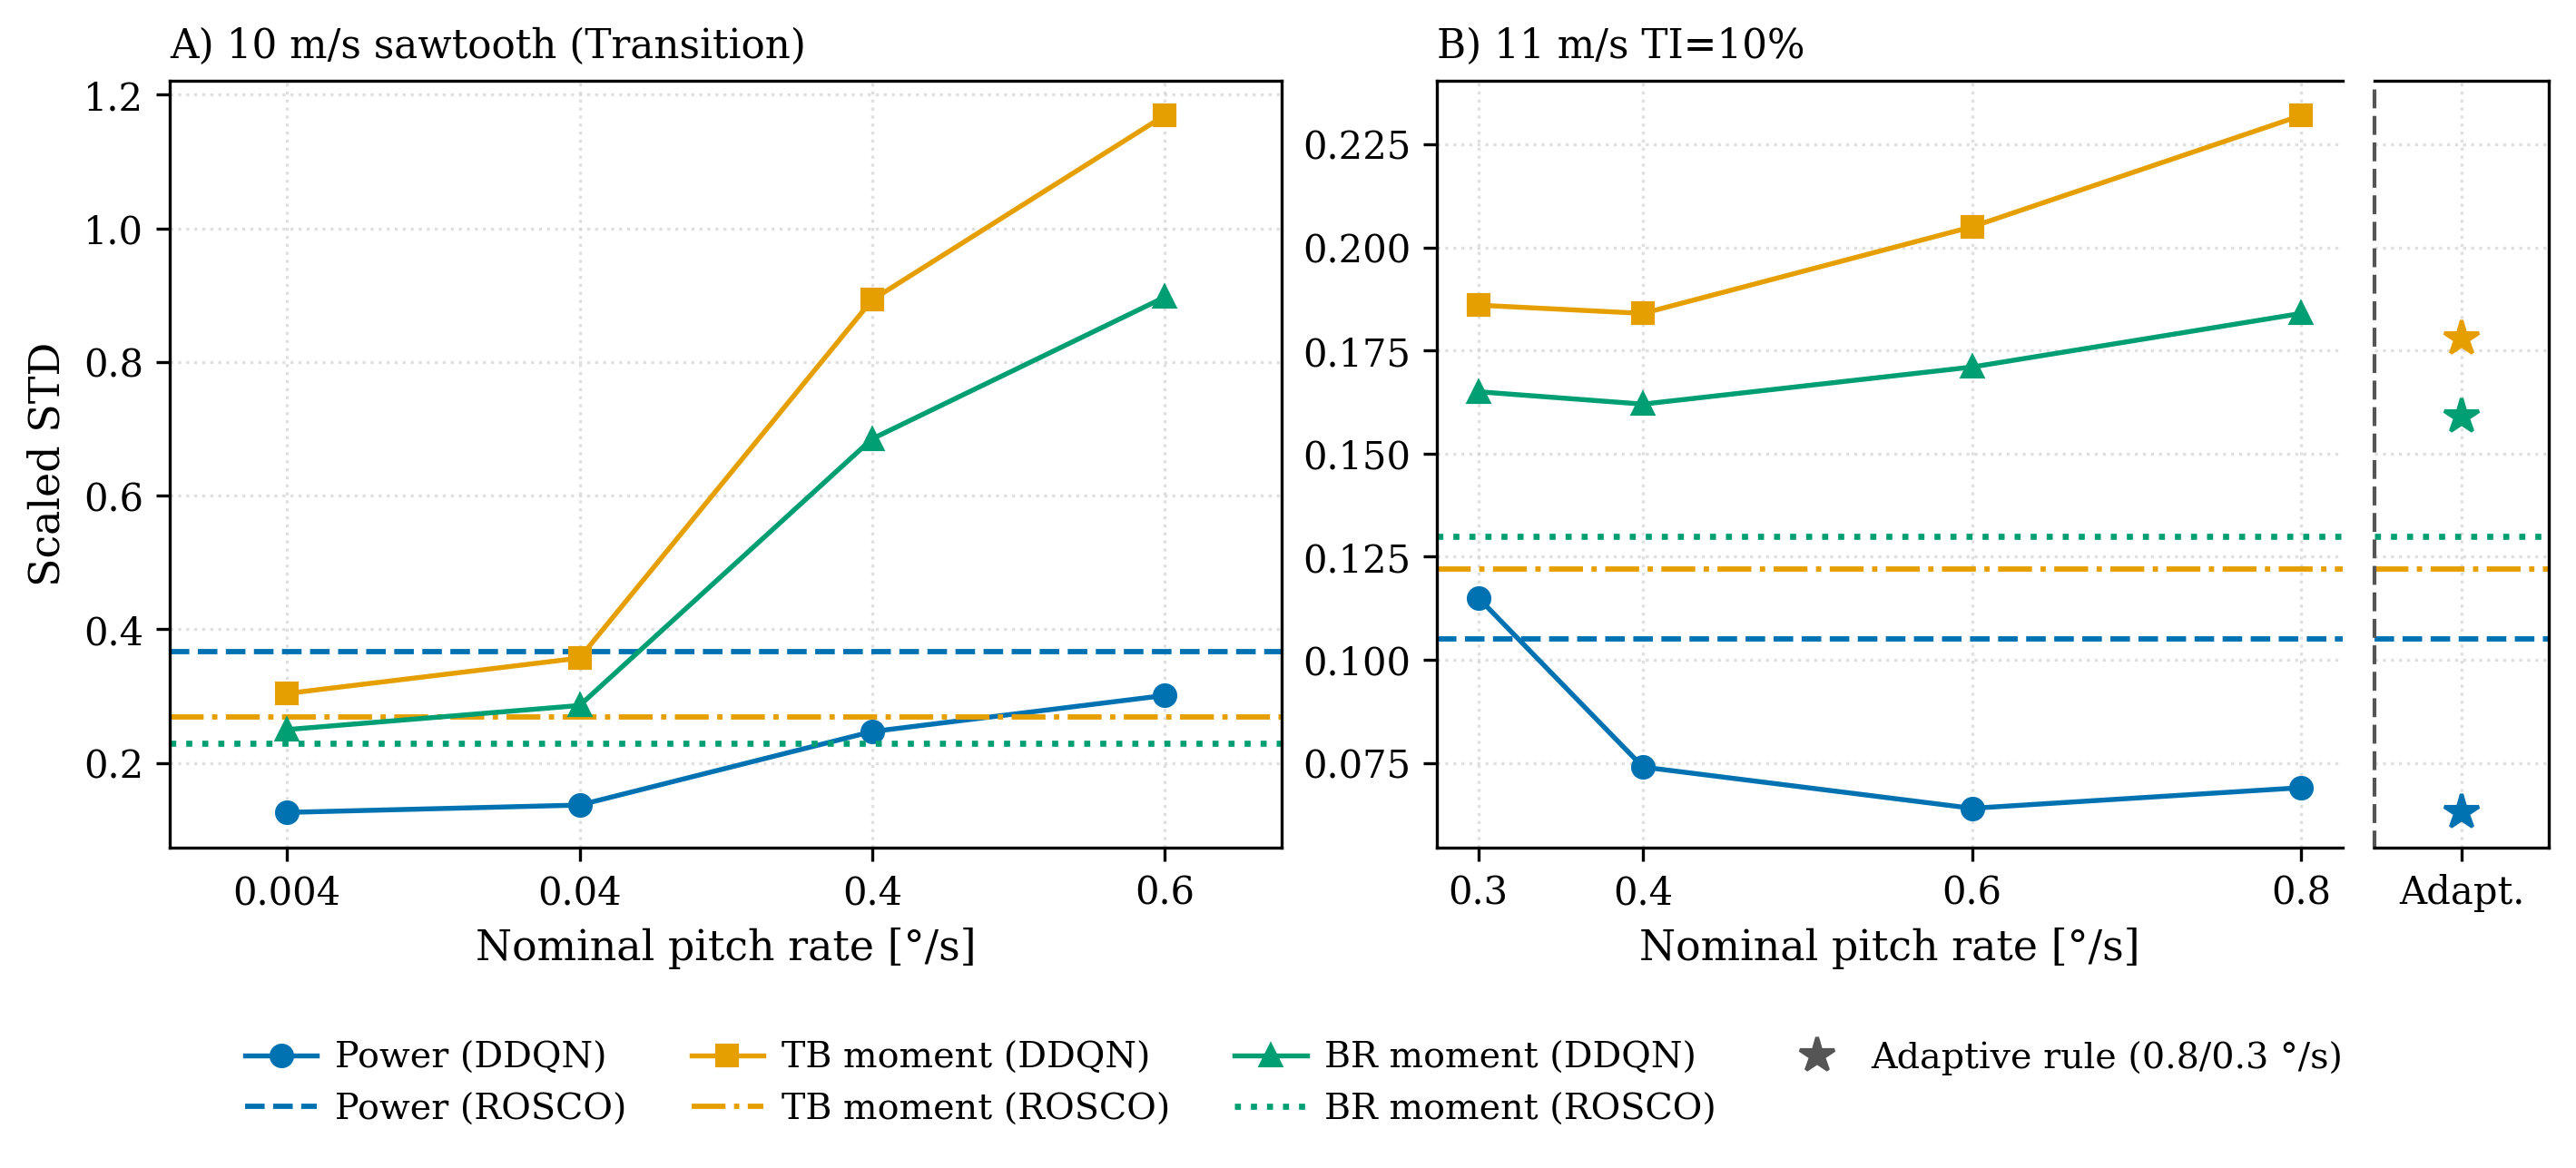

In [5]:
import pandas as pd

fig5 = pd.read_csv(FIG_DIR / "fig5_data.csv")

plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.labelsize": 11,
                     "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 9.5, "mathtext.fontset": "cm"})

CH_STYLE = {  # channel -> (colour, marker, ROSCO line style, ROSCO line width)
    "GenPwr":   ("#0072B2", "o", "--", 1.4),
    "TwrBsMyt": ("#E69F00", "s", "-.", 1.4),
    "RootMyb1": ("#009E73", "^", ":",  1.6),
}
PANELS = {
    "A": {"title": "A) 10 m/s sawtooth (Transition)", "side": None, "ratios": None,
          "categorical": True, "side_xlabel": "Offset at 0.004 °/s [°]"},
    "B": {"title": "B) 11 m/s TI=10%", "side": "adaptive", "ratios": [5.2, 1.0],
          "categorical": False, "side_xlabel": ""},
}


def style_side(ax, ax_side):
    plt.setp(ax_side.get_yticklabels(), visible=False)
    ax_side.tick_params(left=False)
    ax_side.grid(True, linestyle=":", color="#d3d3d3", alpha=0.7)
    ax.spines["right"].set_visible(False)
    ax_side.spines["left"].set_linestyle((0, (4, 3)))
    ax_side.spines["left"].set_color("#555555")
    ax_side.spines["left"].set_linewidth(1.0)


fig = plt.figure(figsize=(9.6, 4.4), dpi=300)
outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.14, left=0.07, right=0.98, bottom=0.26, top=0.90)
handles = {}

for col, (panel, cfg) in enumerate(PANELS.items()):
    d = fig5[fig5["panel"] == panel]
    if cfg["side"]:
        inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0, col],
                                                 width_ratios=cfg["ratios"], wspace=0.06)
        ax = fig.add_subplot(inner[0, 0])
        ax_side = fig.add_subplot(inner[0, 1], sharey=ax)
    else:
        ax, ax_side = fig.add_subplot(outer[0, col]), None

    for ch, (color, marker, ls, lw) in CH_STYLE.items():
        dc = d[d["channel"] == ch]
        fixed = dc[dc["series"] == "fixed"].sort_values("x")
        rosco = dc.loc[dc["series"] == "rosco", "scaled_std"].iloc[0]

        x_plot = range(len(fixed)) if cfg["categorical"] else fixed["x"]
        handles[f"{ch}_ddqn"], = ax.plot(x_plot, fixed["scaled_std"], color=color, marker=marker,
                                         markersize=5.5, linewidth=1.3)
        handles[f"{ch}_rosco"] = ax.axhline(rosco, color=color, linestyle=ls, linewidth=lw)
        if ax_side is not None:
            ax_side.axhline(rosco, color=color, linestyle=ls, linewidth=lw)
            ax_side.plot([0], dc.loc[dc["series"] == cfg["side"], "scaled_std"], color=color,
                         marker="*", markersize=9.5, linestyle="None")

    xs = sorted(d.loc[d["series"] == "fixed", "x"].unique())
    if cfg["categorical"]:
        ax.set_xticks(range(len(xs)))
        ax.set_xlim(-0.4, len(xs) - 0.6)
    else:
        ax.set_xticks(xs)
    ax.set_xticklabels([f"{x:g}" for x in xs])
    ax.set_title(cfg["title"], loc="left", fontsize=10.5, pad=6)
    ax.set_xlabel("Nominal pitch rate [°/s]", labelpad=4)
    if col == 0:
        ax.set_ylabel("Scaled STD", labelpad=4)
    ax.grid(True, linestyle=":", color="#d3d3d3", alpha=0.7)

    if ax_side is not None:
        ax_side.set_xlim(-0.5, 0.5)
        ax_side.set_xticks([0])
        ax_side.set_xticklabels(["Adapt."])
        style_side(ax, ax_side)

# Global legend: each (DDQN, ROSCO) pair shares a column
star = Line2D([], [], color="#555555", marker="*", markersize=9.5, linestyle="None")
legend_h = [handles["GenPwr_ddqn"], handles["GenPwr_rosco"], handles["TwrBsMyt_ddqn"], handles["TwrBsMyt_rosco"],
            handles["RootMyb1_ddqn"], handles["RootMyb1_rosco"], star]
legend_l = ["Power (DDQN)", "Power (ROSCO)", "TB moment (DDQN)", "TB moment (ROSCO)",
            "BR moment (DDQN)", "BR moment (ROSCO)", "Adaptive rule (0.8/0.3 °/s)"]
fig.legend(legend_h, legend_l, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=4,
           frameon=False, columnspacing=1.8, handletextpad=0.5)

plt.savefig(FIG_DIR / "Figure_5.pdf", bbox_inches="tight")
plt.show()